# 1. Setup
## 1.1. GPU Configuration


In [1]:
import torch

# If there's a GPU available...
if torch.cuda.is_available():
    device = torch.device("cuda")
    print('There are %d GPU(s) available.' % torch.cuda.device_count())
    print('We will use the GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 2 GPU(s) available.
We will use the GPU: Tesla T4


## 1.2. Install and Import Libraries


In [2]:
!pip install transformers datasets --quiet

import os
import random
import time
import datetime
import numpy as np
import pandas as pd

import torch
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from torch.nn import CrossEntropyLoss
from torch.optim import AdamW

from transformers import BertTokenizer, BertForSequenceClassification
from transformers import  get_linear_schedule_with_warmup
from transformers import BertConfig

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
)

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Install and Imports complete.")

Install and Imports complete.


## 1.3. Reproducibility

We set a random seed everywhere to ensure reproducibility.

In [3]:
seed_val = 42

random.seed(seed_val)
np.random.seed(seed_val)
torch.manual_seed(seed_val)
torch.cuda.manual_seed_all(seed_val)
# For fully deterministic behavior on CUDA
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Seed set to {seed_val}")

Seed set to 42


# 2. Loading the CLARITY (QEvasion) Dataset

The dataset is hosted on HuggingFace: `ailsntua/QEvasion`. Each instance has:
- `question`: the question asked by the journalist
- `interview_answer`: the full answer given by the president
- `clarity_label`: one of `Clear Reply`, `Ambivalent`, `Clear Non-Reply`

## 2.1. Download & Parse

In [4]:
from datasets import load_dataset

dataset = load_dataset("ailsntua/QEvasion")

print("Train set size:", len(dataset['train']))
print("Test set size:", len(dataset['test']))
print("\nColumns:", dataset['train'].column_names)

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.90M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3448 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/308 [00:00<?, ? examples/s]

Train set size: 3448
Test set size: 308

Columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']


In [5]:
# Convert to pandas for exploration
df_train_full = dataset['train'].to_pandas()
df_test = dataset['test'].to_pandas()

df_train_full[['question', 'interview_answer', 'clarity_label']].head()

,question,interview_answer,clarity_label
0,How would you respond to the accusation that t...,"Well, look, first of all, theI am sincere abou...",Clear Reply
1,Do you think President Xi is being sincere abo...,"Well, look, first of all, theI am sincere abou...",Ambivalent
2,Do you believe the country's slowdown and gro...,"Look, I think China has a difficult economic p...",Ambivalent
3,Are you worried about the meeting between Pre...,"Look, I think China has a difficult economic p...",Ambivalent
4,Is the President's engagement with Asian coun...,"Well, I hope I get to see Mr. Xi sooner than l...",Clear Reply


## 2.2. Exploratory Data Analysis

=== Class Distribution (Training Set) ===
clarity_label
Ambivalent         2040
Clear Reply        1052
Clear Non-Reply     356
Name: count, dtype: int64

clarity_label
Ambivalent         0.592
Clear Reply        0.305
Clear Non-Reply    0.103
Name: proportion, dtype: float64


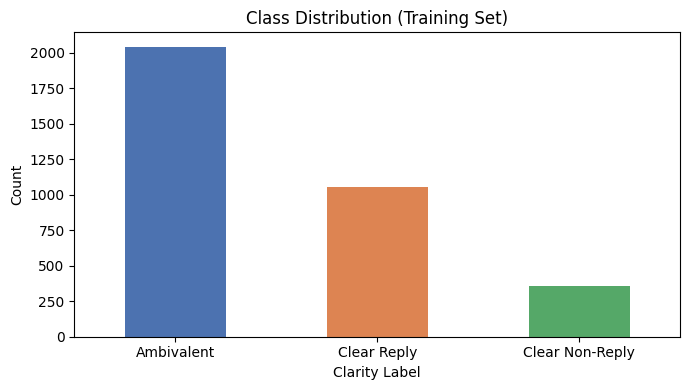

In [6]:
# Class distribution
print("=== Class Distribution (Training Set) ===")
print(df_train_full['clarity_label'].value_counts())
print()
print(df_train_full['clarity_label'].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
df_train_full['clarity_label'].value_counts().plot(
    kind='bar', ax=ax, color=['#4c72b0', '#dd8452', '#55a868']
)
ax.set_title('Class Distribution (Training Set)')
ax.set_xlabel('Clarity Label')
ax.set_ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('/kaggle/working/bert_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

=== Question Length (characters) ===
count    3448.0
mean       84.5
std        51.9
min         3.0
25%        47.0
50%        74.0
75%       110.0
max       464.0
Name: question_len, dtype: float64

=== Answer Length (characters) ===
count     3448.0
mean      1663.3
std       1733.3
min          3.0
25%        309.0
50%       1155.5
75%       2495.0
max      12102.0
Name: answer_len, dtype: float64


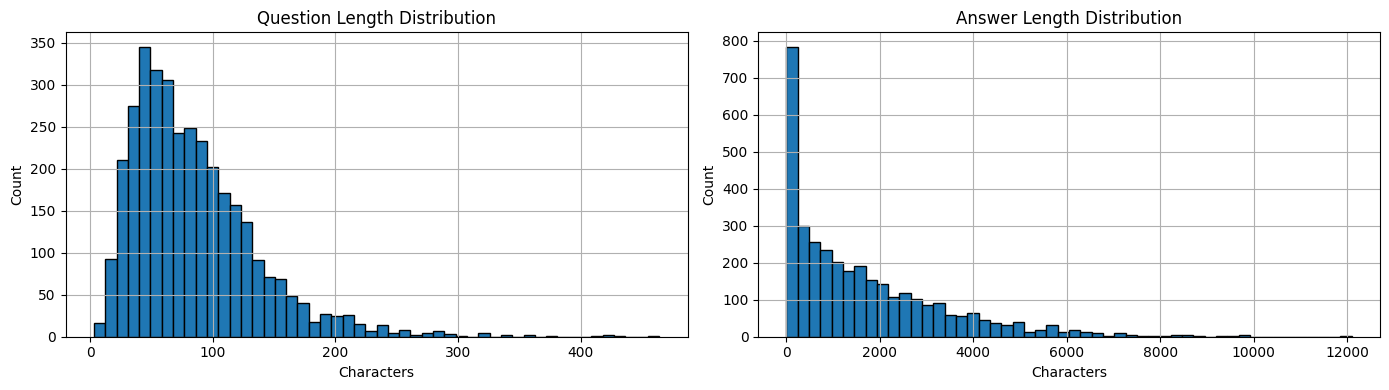

In [7]:
# Text length analysis
df_train_full['question_len'] = df_train_full['question'].astype(str).apply(len)
df_train_full['answer_len'] = df_train_full['interview_answer'].astype(str).apply(len)

print("=== Question Length (characters) ===")
print(df_train_full['question_len'].describe().round(1))
print("\n=== Answer Length (characters) ===")
print(df_train_full['answer_len'].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_train_full['question_len'].hist(bins=50, ax=axes[0], edgecolor='black')
axes[0].set_title('Question Length Distribution')
axes[0].set_xlabel('Characters')
axes[0].set_ylabel('Count')
df_train_full['answer_len'].hist(bins=50, ax=axes[1], edgecolor='black')
axes[1].set_title('Answer Length Distribution')
axes[1].set_xlabel('Characters')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.savefig('/kaggle/working/bert_text_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.3. Label Encoding

We map the clarity labels to integer IDs:
- `Clear Reply` → 0
- `Ambivalent` → 1
- `Clear Non-Reply` → 2

In [8]:
label2id = {'Clear Reply': 0, 'Ambivalent': 1, 'Clear Non-Reply': 2}
id2label = {v: k for k, v in label2id.items()}

df_train_full['label'] = df_train_full['clarity_label'].map(label2id)

print("Label mapping:", label2id)
print("\nLabel counts:")
print(df_train_full['label'].value_counts().sort_index().rename(id2label))

Label mapping: {'Clear Reply': 0, 'Ambivalent': 1, 'Clear Non-Reply': 2}

Label counts:
label
Clear Reply        1052
Ambivalent         2040
Clear Non-Reply     356
Name: count, dtype: int64


# 3. Tokenization & Input Formatting

## 3.1. Input Construction

Since each instance is a **question–answer pair**, we use BERT's native sentence-pair input format:

**[CLS] question [SEP] answer [SEP]**

This is the standard way BERT handles sentence pairs (Devlin et al., 2019). The tokenizer automatically generates `token_type_ids` (0 for question tokens, 1 for answer tokens), which allow BERT to distinguish the two segments via its learned segment embeddings.

## 3.2. Loading the BERT Tokenizer

In [9]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased', do_lower_case=True)
print("BERT tokenizer loaded.")
print(f"Vocabulary size: {tokenizer.vocab_size}")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

BERT tokenizer loaded.
Vocabulary size: 30522


In [10]:
# Quick demo: tokenize one example to verify the [CLS] q [SEP] a [SEP] structure
sample_q = str(df_train_full['question'].iloc[0])
sample_a = str(df_train_full['interview_answer'].iloc[0])

print("Question:", sample_q[:100], "...")
print("Answer:", sample_a[:100], "...")
print()

sample_enc = tokenizer(sample_q, sample_a, add_special_tokens=True)
decoded = tokenizer.decode(sample_enc['input_ids'][:40])
print("Decoded tokens (first 40 IDs):", decoded)
print("Token type IDs (first 40):", sample_enc['token_type_ids'][:40])

Question: How would you respond to the accusation that the United States is containing China while pushing for ...
Answer: Well, look, first of all, theI am sincere about getting the relationship right. And one of the thing ...

Decoded tokens (first 40 IDs): [CLS] how would you respond to the accusation that the united states is containing china while pushing for diplomatic talks? [SEP] well, look, first of all, thei am sincere about getting the relationship right.
Token type IDs (first 40): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 3.3. Choosing Maximum Sequence Length

BERT supports up to 512 tokens. We measure the token length distribution to choose `max_length`.

Token indices sequence length is longer than the specified maximum sequence length for this model (612 > 512). Running this sequence through the model will result in indexing errors


=== Token Length Statistics (question + answer) ===
  Min:    7
  Max:    2595
  Mean:   397.2
  Median: 291.0

  Fit in 128 tokens: 30.2%
  Fit in 256 tokens: 46.0%
  Fit in 384 tokens: 59.5%
  Fit in 512 tokens: 70.6%


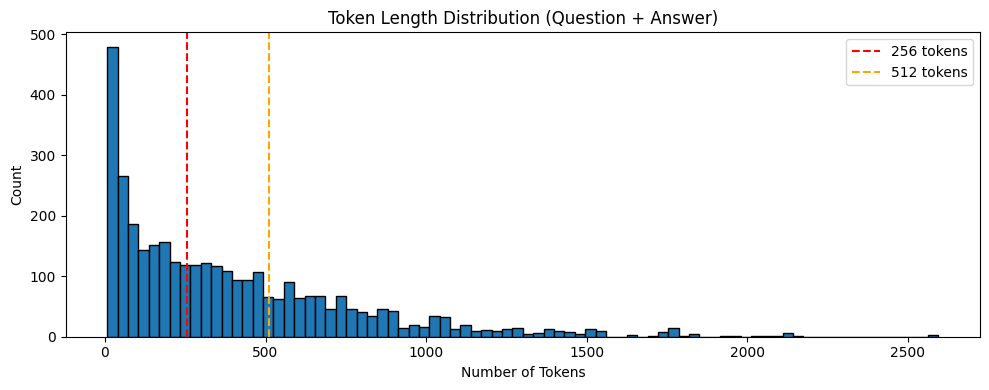

In [11]:
token_lengths = []

for _, row in df_train_full.iterrows():
    enc = tokenizer(str(row['question']), str(row['interview_answer']), add_special_tokens=True)
    token_lengths.append(len(enc['input_ids']))

token_lengths = np.array(token_lengths)

print("=== Token Length Statistics (question + answer) ===")
print(f"  Min:    {token_lengths.min()}")
print(f"  Max:    {token_lengths.max()}")
print(f"  Mean:   {token_lengths.mean():.1f}")
print(f"  Median: {np.median(token_lengths):.1f}")
print()
for ml in [128, 256, 384, 512]:
    pct = (token_lengths <= ml).mean() * 100
    print(f"  Fit in {ml} tokens: {pct:.1f}%")

plt.figure(figsize=(10, 4))
plt.hist(token_lengths, bins=80, edgecolor='black')
plt.axvline(x=256, color='red', linestyle='--', label='256 tokens')
plt.axvline(x=512, color='orange', linestyle='--', label='512 tokens')
plt.title('Token Length Distribution (Question + Answer)')
plt.xlabel('Number of Tokens')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.savefig('/kaggle/working/bert_token_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 3.4. Tokenize the Dataset

We set `MAX_LEN = 512` to retain as much information as possible. Sequences exceeding this are truncated using the `longest_first` strategy — the tokenizer truncates the longer segment first (typically the answer).

In [12]:
MAX_LEN = 512

def tokenize_pairs(questions, answers, tokenizer, max_len):
    """Tokenize question-answer pairs for BERT sentence-pair input."""
    questions_list = [str(q) for q in questions]
    answers_list = [str(a) for a in answers]

    encoded = tokenizer(
        questions_list,
        answers_list,
        add_special_tokens=True,
        max_length=max_len,
        truncation=True,
        padding='max_length',
        return_attention_mask=True,
        return_token_type_ids=True,
        return_tensors='pt',
    )
    return encoded['input_ids'], encoded['attention_mask'], encoded['token_type_ids']

print(f"MAX_LEN = {MAX_LEN}")


MAX_LEN = 512


## 3.5. Training & Validation Split

We use a stratified 85/15 split to preserve class proportions. This is more robust than the tutorial's simple random split, especially with imbalanced classes.

In [13]:
# Function to extract the beginning and end of long texts
def extract_head_tail(text, max_words=350):
    words = str(text).split()
    if len(words) <= max_words:
        return text
    
    # Take the first 175 words and the last 175 words
    half = max_words // 2
    return " ".join(words[:half]) + " ... " + " ".join(words[-half:])

# Extract questions and labels
questions = df_train_full['question'].values
labels = df_train_full['label'].values

# Apply Head+Tail extraction to the raw answers
answers_raw = df_train_full['interview_answer'].values
answers = [extract_head_tail(ans) for ans in answers_raw]

# Create the stratified train/test split
train_questions, val_questions, train_answers, val_answers, train_labels, val_labels = train_test_split(
    questions, answers, labels,
    test_size=0.15,
    random_state=seed_val,
    stratify=labels,
)

print('{:>5,} training samples'.format(len(train_labels)))
print('{:>5,} validation samples'.format(len(val_labels)))
print()
print("Training label distribution:")
print(pd.Series(train_labels).value_counts().sort_index().rename(id2label))
print()
print("Validation label distribution:")
print(pd.Series(val_labels).value_counts().sort_index().rename(id2label))

2,930 training samples
  518 validation samples

Training label distribution:
Clear Reply         894
Ambivalent         1734
Clear Non-Reply     302
Name: count, dtype: int64

Validation label distribution:
Clear Reply        158
Ambivalent         306
Clear Non-Reply     54
Name: count, dtype: int64


In [14]:
print("Tokenizing training set...")
train_input_ids, train_attention_masks, train_token_type_ids = tokenize_pairs(
    train_questions, train_answers, tokenizer, MAX_LEN
)
train_labels_tensor = torch.tensor(train_labels, dtype=torch.long)

print("Tokenizing validation set...")
val_input_ids, val_attention_masks, val_token_type_ids = tokenize_pairs(
    val_questions, val_answers, tokenizer, MAX_LEN
)
val_labels_tensor = torch.tensor(val_labels, dtype=torch.long)

print("Done!")
print(f"  Training input shape:   {train_input_ids.shape}")
print(f"  Validation input shape: {val_input_ids.shape}")

Tokenizing training set...
Tokenizing validation set...
Done!
  Training input shape:   torch.Size([2930, 512])
  Validation input shape: torch.Size([518, 512])


In [15]:
# Verify tokenization structure
idx = 0
decoded = tokenizer.decode(train_input_ids[idx], skip_special_tokens=False)
print("Label:", id2label[train_labels[idx]])
print("Decoded (first 300 chars):", decoded[:300])
print()
print("Token type IDs (first 30):", train_token_type_ids[idx][:30].tolist())

Label: Ambivalent
Decoded (first 300 chars): [CLS] do you still think it was the right decision to intervene in this debate? [SEP] well, first of all, let me repeat : this is a decision for the people of the united kingdom to make. i ' m not coming here to fix any votes. i ' m not casting a vote myself. i ' m offering my opinion. and in democr

Token type IDs (first 30): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 3.6. Create DataLoaders

In [16]:
batch_size = 16

train_dataset = TensorDataset(
    train_input_ids, train_attention_masks, train_token_type_ids, train_labels_tensor
)
train_dataloader = DataLoader(
    train_dataset,
    sampler=RandomSampler(train_dataset),
    batch_size=batch_size,
)

val_dataset = TensorDataset(
    val_input_ids, val_attention_masks, val_token_type_ids, val_labels_tensor
)
validation_dataloader = DataLoader(
    val_dataset,
    sampler=SequentialSampler(val_dataset),
    batch_size=batch_size,
)

print(f"Batch size: {batch_size}")
print(f"Training batches:   {len(train_dataloader)}")
print(f"Validation batches: {len(validation_dataloader)}")

Batch size: 16
Training batches:   184
Validation batches: 33


# 4. Train Our Classification Model

## 4.1. BertForSequenceClassification

We load the pretrained `bert-base-uncased` model with a single linear classification layer on top for 3 output labels.

We also compute **class weights** (inverse frequency) and use a weighted `CrossEntropyLoss` to handle the class imbalance.

In [17]:


config = BertConfig.from_pretrained('bert-base-uncased')
config.num_labels = 3
config.classifier_dropout = 0.3

model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    config=config,
)
model.to(device)

params = list(model.named_parameters())
print('The BERT model has {:} different named parameters.\n'.format(len(params)))

print('==== Embedding Layer ====\n')
for p in params[0:5]:
    print("{:<55} {:>12}".format(p[0], str(tuple(p[1].size()))))

print('\n==== First Transformer ====\n')
for p in params[5:21]:
    print("{:<55} {:>12}".format(p[0], str(tuple(p[1].size()))))

print('\n==== Output Layer ====\n')
for p in params[-4:]:
    print("{:<55} {:>12}".format(p[0], str(tuple(p[1].size()))))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


The BERT model has 201 different named parameters.

==== Embedding Layer ====

bert.embeddings.word_embeddings.weight                  (30522, 768)
bert.embeddings.position_embeddings.weight                (512, 768)
bert.embeddings.token_type_embeddings.weight                (2, 768)
bert.embeddings.LayerNorm.weight                              (768,)
bert.embeddings.LayerNorm.bias                                (768,)

==== First Transformer ====

bert.encoder.layer.0.attention.self.query.weight          (768, 768)
bert.encoder.layer.0.attention.self.query.bias                (768,)
bert.encoder.layer.0.attention.self.key.weight            (768, 768)
bert.encoder.layer.0.attention.self.key.bias                  (768,)
bert.encoder.layer.0.attention.self.value.weight          (768, 768)
bert.encoder.layer.0.attention.self.value.bias                (768,)
bert.encoder.layer.0.attention.output.dense.weight        (768, 768)
bert.encoder.layer.0.attention.output.dense.bias              (

In [18]:
# Compute balanced class weights to handle class imbalance
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels,
)

# Move weights to the correct device
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

print("Class weights:")
for i, w in enumerate(class_weights):
    print(f"  {id2label[i]}: {w:.4f}")

# Weighted cross-entropy loss with label smoothing to improve generalization
loss_fn = CrossEntropyLoss(weight=class_weights_tensor, label_smoothing=0.1)

Class weights:
  Clear Reply: 1.0925
  Ambivalent: 0.5632
  Clear Non-Reply: 3.2340


## 4.2. Optimizer & Learning Rate Scheduler

- **Batch size**: 16
- **Learning rate (AdamW)**: 3e-5
- **Epochs**: 4
- **Warmup**: 20% of total steps, then linear decay

In [19]:
epochs = 4
learning_rate = 3e-5

optimizer = AdamW(model.parameters(), lr=learning_rate, eps=1e-8, weight_decay=0.01)

total_steps = len(train_dataloader) * epochs
warmup_steps = int(0.2 * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

print(f"Epochs:       {epochs}")
print(f"LR:           {learning_rate}")
print(f"Total steps:  {total_steps}")
print(f"Warmup steps: {warmup_steps}")

Epochs:       4
LR:           3e-05
Total steps:  736
Warmup steps: 147


## 4.3. Training Loop

**Training:** Unpack data → GPU → zero gradients → forward pass → weighted loss → backward → clip gradients → optimizer step → scheduler step

**Validation:** Unpack data → GPU → forward pass (no gradients) → loss & metrics

We track F1-score (weighted and macro) in addition to accuracy and loss, as required by the assignment.

In [20]:
def format_time(elapsed):
    '''Takes a time in seconds and returns a string hh:mm:ss'''
    elapsed_rounded = int(round(elapsed))
    return str(datetime.timedelta(seconds=elapsed_rounded))

def flat_accuracy(preds, labels):
    pred_flat = np.argmax(preds, axis=1).flatten()
    labels_flat = labels.flatten()
    return np.sum(pred_flat == labels_flat) / len(labels_flat)

In [21]:
training_stats = []
best_val_f1 = 0.0
best_model_state = None
best_epoch = 0
total_t0 = time.time()

for epoch_i in range(0, epochs):

    # ========================================
    #               Training
    # ========================================
    print("")
    print('======== Epoch {:} / {:} ========'.format(epoch_i + 1, epochs))
    print('Training...')

    t0 = time.time()
    total_train_loss = 0
    model.train()

    for step, batch in enumerate(train_dataloader):

        if step % 40 == 0 and not step == 0:
            elapsed = format_time(time.time() - t0)
            print('  Batch {:>5,}  of  {:>5,}.    Elapsed: {:}.'.format(
                step, len(train_dataloader), elapsed))

        b_input_ids = batch[0].to(device)
        b_input_mask = batch[1].to(device)
        b_token_type_ids = batch[2].to(device)
        b_labels = batch[3].to(device)

        model.zero_grad()

        result = model(b_input_ids,
                       token_type_ids=b_token_type_ids,
                       attention_mask=b_input_mask,
                       return_dict=True)

        logits = result.logits
        loss = loss_fn(logits, b_labels)
        total_train_loss += loss.item()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

    avg_train_loss = total_train_loss / len(train_dataloader)
    training_time = format_time(time.time() - t0)

    print("")
    print("  Average training loss: {0:.4f}".format(avg_train_loss))
    print("  Training epoch took:   {:}".format(training_time))

    # ========================================
    #               Validation
    # ========================================
    print("")
    print("Running Validation...")

    t0 = time.time()
    model.eval()

    total_eval_accuracy = 0
    total_eval_loss = 0
    all_preds = []
    all_true = []

    for batch in validation_dataloader:

        b_input_ids = batch[0].to(device)
        b_input_mask = batch[1].to(device)
        b_token_type_ids = batch[2].to(device)
        b_labels = batch[3].to(device)

        with torch.no_grad():
            result = model(b_input_ids,
                           token_type_ids=b_token_type_ids,
                           attention_mask=b_input_mask,
                           return_dict=True)

        logits = result.logits
        loss = loss_fn(logits, b_labels)
        total_eval_loss += loss.item()

        logits = logits.detach().cpu().numpy()
        label_ids = b_labels.to('cpu').numpy()

        total_eval_accuracy += flat_accuracy(logits, label_ids)
        all_preds.extend(np.argmax(logits, axis=1).flatten().tolist())
        all_true.extend(label_ids.flatten().tolist())

    avg_val_accuracy = total_eval_accuracy / len(validation_dataloader)
    avg_val_loss = total_eval_loss / len(validation_dataloader)
    val_f1 = f1_score(all_true, all_preds, average='weighted')
    val_macro_f1 = f1_score(all_true, all_preds, average='macro')
    validation_time = format_time(time.time() - t0)

    print("  Accuracy:        {0:.4f}".format(avg_val_accuracy))
    print("  Validation Loss: {0:.4f}".format(avg_val_loss))
    print("  F1 (weighted):   {0:.4f}".format(val_f1))
    print("  F1 (macro):      {0:.4f}".format(val_macro_f1))
    print("  Validation took: {:}".format(validation_time))
    
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        best_epoch = epoch_i + 1
        
    training_stats.append({
        'epoch': epoch_i + 1,
        'Training Loss': avg_train_loss,
        'Valid. Loss': avg_val_loss,
        'Valid. Accur.': avg_val_accuracy,
        'Valid. F1 (weighted)': val_f1,
        'Valid. F1 (macro)': val_macro_f1,
        'Training Time': training_time,
        'Validation Time': validation_time,
    })

print("")
print("Training complete!")
if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print(f"\nRestored best model from epoch {best_epoch} (F1={best_val_f1:.4f})")
print("Total training took {:} (h:mm:ss)".format(format_time(time.time()-total_t0)))


======== Epoch 1 / 4 ========
Training...
  Batch    40  of    184.    Elapsed: 0:00:56.
  Batch    80  of    184.    Elapsed: 0:01:59.
  Batch   120  of    184.    Elapsed: 0:03:05.
  Batch   160  of    184.    Elapsed: 0:04:10.

  Average training loss: 1.1730
  Training epoch took:   0:04:49

Running Validation...
  Accuracy:        0.4880
  Validation Loss: 1.0193
  F1 (weighted):   0.4639
  F1 (macro):      0.4794
  Validation took: 0:00:18

======== Epoch 2 / 4 ========
Training...
  Batch    40  of    184.    Elapsed: 0:01:04.
  Batch    80  of    184.    Elapsed: 0:02:09.
  Batch   120  of    184.    Elapsed: 0:03:14.
  Batch   160  of    184.    Elapsed: 0:04:20.

  Average training loss: 0.9810
  Training epoch took:   0:04:58

Running Validation...
  Accuracy:        0.6395
  Validation Loss: 0.9587
  F1 (weighted):   0.6452
  F1 (macro):      0.6203
  Validation took: 0:00:18

======== Epoch 3 / 4 ========
Training...
  Batch    40  of    184.    Elapsed: 0:01:04.
  Batch 

# 5. Training Results

In [22]:
pd.options.display.precision = 4
df_stats = pd.DataFrame(data=training_stats)
df_stats = df_stats.set_index('epoch')
df_stats

,Training Loss,Valid. Loss,Valid. Accur.,Valid. F1 (weighted),Valid. F1 (macro),Training Time,Validation Time
epoch,,,,,,,
1,1.1730,1.0193,0.4880,0.4639,0.4794,0:04:49,0:00:18
2,0.9810,0.9587,0.6395,0.6452,0.6203,0:04:58,0:00:18
3,0.8410,0.9570,0.6698,0.6741,0.6578,0:04:58,0:00:18
4,0.6981,1.0073,0.6717,0.6749,0.6538,0:04:58,0:00:18


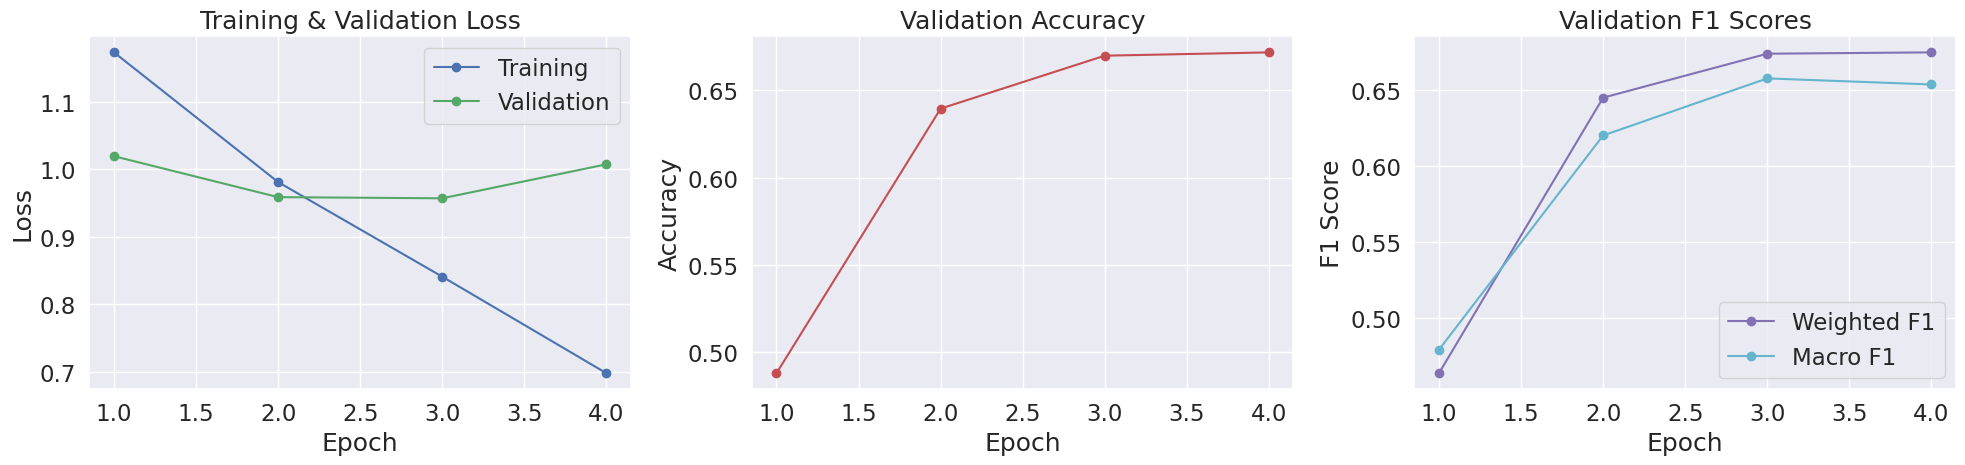

In [23]:
sns.set(style='darkgrid')
sns.set(font_scale=1.5)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(df_stats['Training Loss'], 'b-o', label="Training")
axes[0].plot(df_stats['Valid. Loss'], 'g-o', label="Validation")
axes[0].set_title("Training & Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(df_stats['Valid. Accur.'], 'r-o')
axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

axes[2].plot(df_stats['Valid. F1 (weighted)'], 'm-o', label="Weighted F1")
axes[2].plot(df_stats['Valid. F1 (macro)'], 'c-o', label="Macro F1")
axes[2].set_title("Validation F1 Scores")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("F1 Score")
axes[2].legend()

plt.tight_layout()
plt.savefig('/kaggle/working/bert_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# 6. Detailed Evaluation on Validation Set

In [24]:
model.eval()
all_preds = []
all_labels_eval = []

for batch in validation_dataloader:
    b_input_ids = batch[0].to(device)
    b_input_mask = batch[1].to(device)
    b_token_type_ids = batch[2].to(device)
    b_labels = batch[3].to(device)

    with torch.no_grad():
        result = model(b_input_ids,
                       token_type_ids=b_token_type_ids,
                       attention_mask=b_input_mask,
                       return_dict=True)

    logits = result.logits.detach().cpu().numpy()
    label_ids = b_labels.to('cpu').numpy()
    all_preds.extend(np.argmax(logits, axis=1).flatten().tolist())
    all_labels_eval.extend(label_ids.flatten().tolist())

target_names = [id2label[i] for i in range(3)]

print("=== Classification Report ===\n")
print(classification_report(all_labels_eval, all_preds, target_names=target_names, digits=4))

print(f"Accuracy:          {accuracy_score(all_labels_eval, all_preds):.4f}")
print(f"F1 (weighted):     {f1_score(all_labels_eval, all_preds, average='weighted'):.4f}")
print(f"F1 (macro):        {f1_score(all_labels_eval, all_preds, average='macro'):.4f}")
print(f"Precision (macro): {precision_score(all_labels_eval, all_preds, average='macro'):.4f}")
print(f"Recall (macro):    {recall_score(all_labels_eval, all_preds, average='macro'):.4f}")

=== Classification Report ===

                 precision    recall  f1-score   support

    Clear Reply     0.5611    0.6392    0.5976       158
     Ambivalent     0.7581    0.6863    0.7204       306
Clear Non-Reply     0.6066    0.6852    0.6435        54

       accuracy                         0.6718       518
      macro avg     0.6419    0.6702    0.6538       518
   weighted avg     0.6822    0.6718    0.6749       518

Accuracy:          0.6718
F1 (weighted):     0.6749
F1 (macro):        0.6538
Precision (macro): 0.6419
Recall (macro):    0.6702


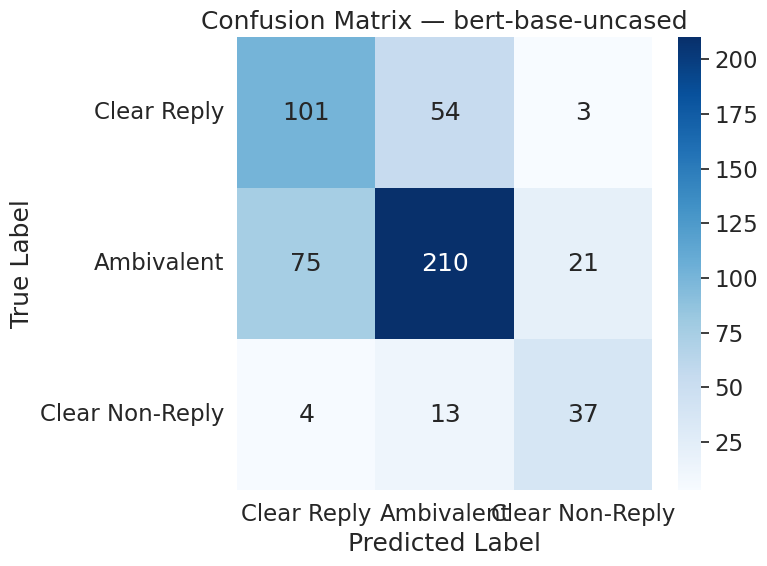

In [25]:
cm = confusion_matrix(all_labels_eval, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix — bert-base-uncased')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('/kaggle/working/bert_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# 7. Error Analysis

We examine misclassified examples to understand model failures.

In [26]:
val_results = pd.DataFrame({
    'question': val_questions,
    'answer': val_answers,
    'true_label': [id2label[l] for l in val_labels],
    'predicted_label': [id2label[p] for p in all_preds],
    'correct': [t == p for t, p in zip(all_labels_eval, all_preds)],
})

errors = val_results[~val_results['correct']].copy()
print(f"Total validation samples: {len(val_results)}")
print(f"Misclassified:            {len(errors)}")
print(f"Error rate:               {len(errors)/len(val_results):.2%}")
print()
print("=== Errors by True Label ===")
print(errors['true_label'].value_counts())
print()
print("=== Confusion Pairs (True -> Predicted) ===")
print(errors.groupby(['true_label', 'predicted_label']).size().sort_values(ascending=False))

Total validation samples: 518
Misclassified:            170
Error rate:               32.82%

=== Errors by True Label ===
true_label
Ambivalent         96
Clear Reply        57
Clear Non-Reply    17
Name: count, dtype: int64

=== Confusion Pairs (True -> Predicted) ===
true_label       predicted_label
Ambivalent       Clear Reply        75
Clear Reply      Ambivalent         54
Ambivalent       Clear Non-Reply    21
Clear Non-Reply  Ambivalent         13
                 Clear Reply         4
Clear Reply      Clear Non-Reply     3
dtype: int64


In [27]:
print("=" * 80)
print("SAMPLE MISCLASSIFIED EXAMPLES")
print("=" * 80)

for i, (_, row) in enumerate(errors.head(5).iterrows()):
    print(f"\n--- Example {i+1} ---")
    print(f"True: {row['true_label']}  |  Predicted: {row['predicted_label']}")
    print(f"Question: {str(row['question'])[:250]}")
    print(f"Answer:   {str(row['answer'])[:400]}")
    print("-" * 80)

SAMPLE MISCLASSIFIED EXAMPLES

--- Example 1 ---
True: Clear Reply  |  Predicted: Ambivalent
Question:  Is ASEAN ready for the more advanced role in world affairs the U.S. would like to see it play?
Answer:   I have not--I've been out of town, so I'm just seeing the press reports. I have not had a full briefing on Israel's intentions and what they've communicated to our administration. But this kind of activity is never helpful when it comes to peace negotiations. And I'm concerned that we're not seeing each side make the extra effort involved to get a breakthrough that could finally create a framework
--------------------------------------------------------------------------------

--- Example 2 ---
True: Ambivalent  |  Predicted: Clear Reply
Question: The reason for selecting the Vice President to lead the response.
Answer:   Well, Mike is not a czar. He's Vice President. He's in the administration. But I'm having everybody report to Mike. Mike has been very good, very adept. Anybody

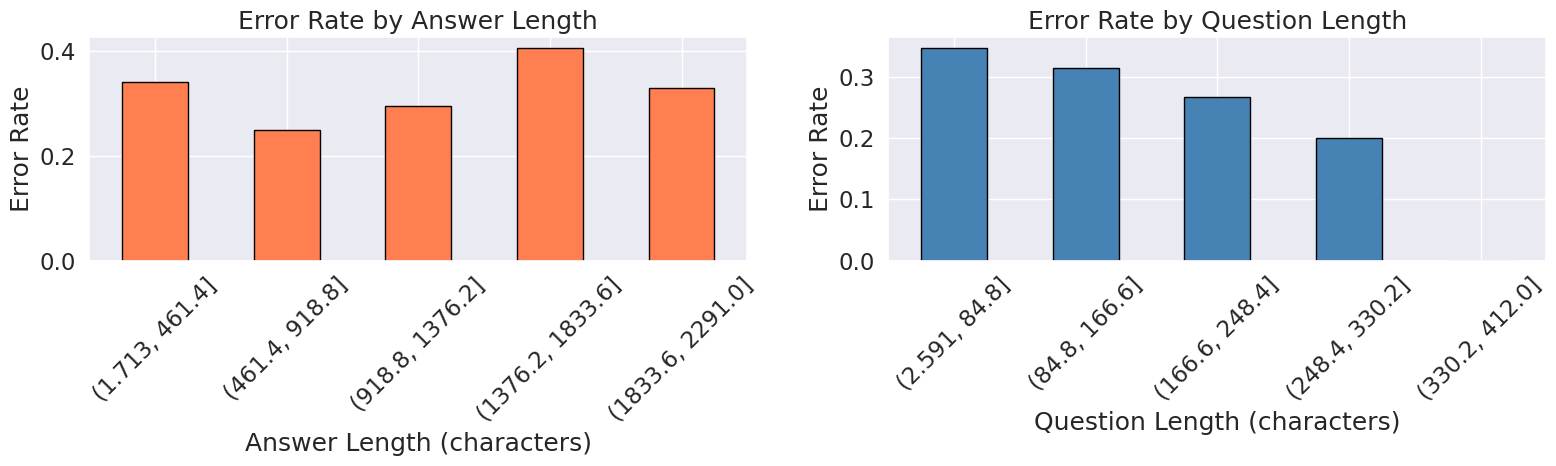

In [28]:
# Error rate by answer length
val_results['a_len'] = val_results['answer'].astype(str).apply(len)
val_results['q_len'] = val_results['question'].astype(str).apply(len)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

val_results['a_len_bin'] = pd.cut(val_results['a_len'], bins=5)
error_by_alen = val_results.groupby('a_len_bin', observed=True)['correct'].apply(lambda x: 1 - x.mean())
error_by_alen.plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Error Rate by Answer Length')
axes[0].set_xlabel('Answer Length (characters)')
axes[0].set_ylabel('Error Rate')
axes[0].tick_params(axis='x', rotation=45)

val_results['q_len_bin'] = pd.cut(val_results['q_len'], bins=5)
error_by_qlen = val_results.groupby('q_len_bin', observed=True)['correct'].apply(lambda x: 1 - x.mean())
error_by_qlen.plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
axes[1].set_title('Error Rate by Question Length')
axes[1].set_xlabel('Question Length (characters)')
axes[1].set_ylabel('Error Rate')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('/kaggle/working/bert_error_rate_by_length.png', dpi=150, bbox_inches='tight')
plt.show()

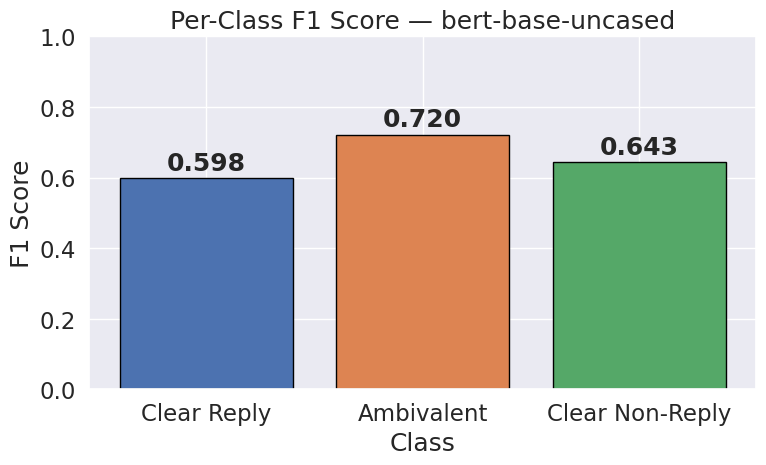

In [29]:
# Per-class F1 bar chart
from sklearn.metrics import f1_score as f1_per_class

per_class_f1 = f1_per_class(all_labels_eval, all_preds, average=None, labels=[0, 1, 2])

plt.figure(figsize=(8, 5))
bars = plt.bar(target_names, per_class_f1, color=['#4c72b0', '#dd8452', '#55a868'], edgecolor='black')
for bar, val in zip(bars, per_class_f1):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontweight='bold')
plt.title('Per-Class F1 Score — bert-base-uncased')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.ylim(0, 1.0)
plt.tight_layout()
plt.savefig('/kaggle/working/bert_per_class_f1.png', dpi=150, bbox_inches='tight')
plt.show()

# 8. Predictions on Test Set & Kaggle Submission

In [30]:
# Extract test questions
test_questions = df_test['question'].values

test_answers_raw = df_test['interview_answer'].values
test_answers = [extract_head_tail(ans) for ans in test_answers_raw]

print(f"Test set size: {len(test_questions)}")
print("Tokenizing test set...")

# Tokenize test set using the same sentence-pair format as training
test_input_ids, test_attention_masks, test_token_type_ids = tokenize_pairs(
    test_questions, test_answers, tokenizer, MAX_LEN
)

# Create the test DataLoader
test_dataset = TensorDataset(test_input_ids, test_attention_masks, test_token_type_ids)
test_dataloader = DataLoader(
    test_dataset, sampler=SequentialSampler(test_dataset), batch_size=batch_size
)

print(f"Test batches: {len(test_dataloader)}")

Test set size: 308
Tokenizing test set...
Test batches: 20


In [31]:
print('Predicting labels for {:,} test samples...'.format(len(test_input_ids)))

model.eval()
test_predictions = []

for batch in test_dataloader:
    b_input_ids = batch[0].to(device)
    b_input_mask = batch[1].to(device)
    b_token_type_ids = batch[2].to(device)

    with torch.no_grad():
        result = model(b_input_ids,
                       token_type_ids=b_token_type_ids,
                       attention_mask=b_input_mask,
                       return_dict=True)

    logits = result.logits.detach().cpu().numpy()
    test_predictions.extend(np.argmax(logits, axis=1).flatten().tolist())

print('    DONE.')
print(f"Generated {len(test_predictions)} predictions.")

Predicting labels for 308 test samples...
    DONE.
Generated 308 predictions.


In [32]:
test_pred_labels = [id2label[p] for p in test_predictions]

print("Test prediction distribution:")
print(pd.Series(test_pred_labels).value_counts())

Test prediction distribution:
Ambivalent         179
Clear Reply         91
Clear Non-Reply     38
Name: count, dtype: int64


In [33]:
submission = pd.DataFrame({
    'Id': df_test['index'].values,
    'Predicted': test_pred_labels,
})

submission.to_csv('/kaggle/working/submission_bert-base-uncased.csv', index=False)
print("Saved: submission_bert-base-uncased.csv")
print(f"Shape: {submission.shape}")
submission.head(10)

Saved: submission_bert-base-uncased.csv
Shape: (308, 2)


,Id,Predicted
0,0,Ambivalent
1,1,Ambivalent
2,2,Ambivalent
3,3,Clear Non-Reply
4,4,Clear Reply
5,5,Ambivalent
6,6,Ambivalent
7,7,Ambivalent
8,8,Ambivalent
9,9,Ambivalent


# 9. Summary

| Setting | Value |
|---|---|
| **Model** | `bert-base-uncased` (110M params, L=12, H=768, A=12) |
| **Input format** | `[CLS] question [SEP] answer [SEP]` with `token_type_ids` |
| **MAX_LEN** | 512 |
| **Batch size** | 16 |
| **Learning rate** | 3e-5 (AdamW, weight_decay=0.01) |
| **Scheduler** | Linear warmup (20%) + linear decay |
| **Epochs** | 4 |
| **Gradient clipping** | max_norm = 1.0 |
| **Loss** | Weighted CrossEntropyLoss (balanced class weights) |
| **Train/Val split** | 85/15 stratified |
| **Seed** | 42 |